In [1]:
import pandas as pd
from sklearn import tree
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as pltṁ

In [8]:
data = {
'Age': ['old', 'old', 'old', 'mid', 'mid', 'mid', 'mid', 'new', 'new', 'new'],
'Competition': ['yes', 'no', 'no', 'yes', 'yes', 'no', 'no', 'yes', 'no', 'no'],
'Type': ['software', 'software', 'hardware', 'software', 'hardware',
'hardware', 'software', 'software', 'hardware', 'software'],
'Profit': ['down', 'down', 'down', 'down', 'down', 'up', 'up', 'up', 'up', 'up']
}
for col in data:
   data[col] = [str(x) for x in data[col]]
df = pd.DataFrame(data)
df

,Age,Competition,Type,Profit
0,old,yes,software,down
1,old,no,software,down
2,old,no,hardware,down
3,mid,yes,software,down
4,mid,yes,hardware,down
5,mid,no,hardware,up
6,mid,no,software,up
7,new,yes,software,up
8,new,no,hardware,up
9,new,no,software,up


In [9]:
le_age = LabelEncoder()
le_comp = LabelEncoder()
le_type = LabelEncoder()
le_profit = LabelEncoder()

df['Age'] = le_age.fit_transform(df['Age'])
df['Competition'] = le_comp.fit_transform(df['Competition'])
df['Type'] = le_type.fit_transform(df['Type'])
df['Profit'] = le_profit.fit_transform(df['Profit'])
print("Dataset after applying encoding:\n\n")
df

# Step 3: Split Features and Target
X = df[['Age', 'Competition', 'Type']]
y = df['Profit']
print("Input Features:\n")
print(X)
print("Output Features:\n")
print(y)

Dataset after applying encoding:


Input Features:

   Age  Competition  Type
0    2            1     1
1    2            0     1
2    2            0     0
3    0            1     1
4    0            1     0
5    0            0     0
6    0            0     1
7    1            1     1
8    1            0     0
9    1            0     1
Output Features:

0    0
1    0
2    0
3    0
4    0
5    1
6    1
7    1
8    1
9    1
Name: Profit, dtype: int64


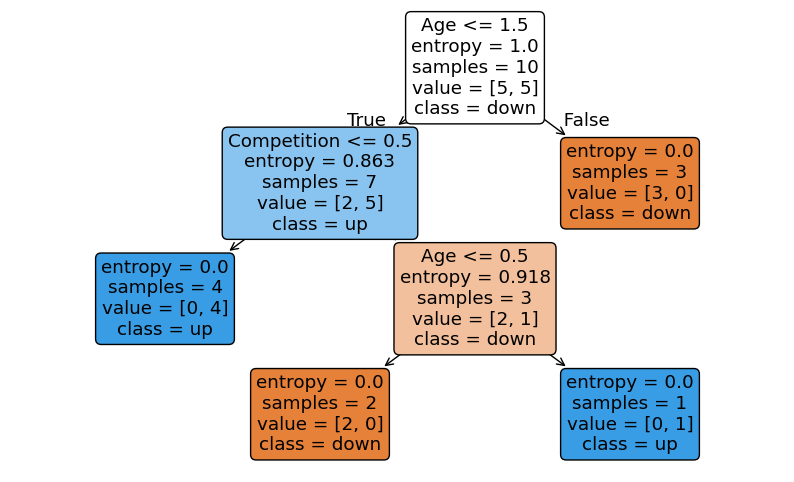

In [10]:
# Step 4: Train Decision Tree (using Entropy)
model = tree.DecisionTreeClassifier(criterion='entropy', random_state=4)
model.fit(X, y)
# Step 5: Visualize the Decision Tree (Fixed)
plt.figure(figsize=(10, 6)) #new blank figure with size figsize=(10, 6)
tree.plot_tree(model,
feature_names=['Age', 'Competition', 'Type'],
class_names=[str(c) for c in le_profit.classes_],
filled=True,
rounded=True)
plt.show()